In [ ]:
import pandas as pd
df = pd.read_csv("/content/insurance.csv")




In [ ]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19.0,female,27.900,0.0,yes,southwest,16884.92400
1,18.0,male,33.770,1.0,no,southeast,1725.55230
2,28.0,male,33.000,3.0,no,southeast,4449.46200
3,33.0,male,22.705,0.0,no,northwest,21984.47061
4,32.0,male,28.880,0.0,no,northwest,3866.85520


In [ ]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50.0,male,30.97,3.0,no,northwest,10600.5483
1334,18.0,female,31.92,0.0,no,northeast,2205.9808
1335,18.0,female,36.85,0.0,no,southeast,1629.8335
1336,21.0,female,25.80,0.0,no,southwest,2007.9450
1337,61.0,female,29.07,0.0,yes,northwest,29141.3603


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1335 non-null   float64
 1   sex       1336 non-null   object 
 2   bmi       1335 non-null   float64
 3   children  1336 non-null   float64
 4   smoker    1336 non-null   object 
 5   region    1336 non-null   object 
 6   charges   1337 non-null   float64
dtypes: float64(4), object(3)
memory usage: 73.3+ KB


In [ ]:
df.describe()

,age,bmi,children,charges
count,1335.000000,1335.000000,1336.000000,1337.000000
mean,39.238951,30.657903,1.096557,13271.853650
std,14.047648,6.101257,1.205650,12114.429349
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.255000,0.000000,4738.268200
50%,39.000000,30.400000,1.000000,9377.904700
75%,51.000000,34.637500,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
df.isnull().sum()

,0
age,3
sex,2
bmi,3
children,2
smoker,2
region,2
charges,1


In [ ]:
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])

Rows: 1338
Columns: 7


In [ ]:
print(df.columns.tolist())

['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [ ]:
df.dtypes

,0
age,float64
sex,object
bmi,float64
children,float64
smoker,object
region,object
charges,float64


In [ ]:
df_input = ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
df_target =['charges']
print("input variable:",df_input)
print("target variable:",df_target)

input variable: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
target variable: ['charges']


In [ ]:
# check duplicate rows
df.duplicated().sum()

np.int64(1)

In [ ]:
# drop duplicate
df = df.drop_duplicates()
df. duplicated().sum()

np.int64(0)

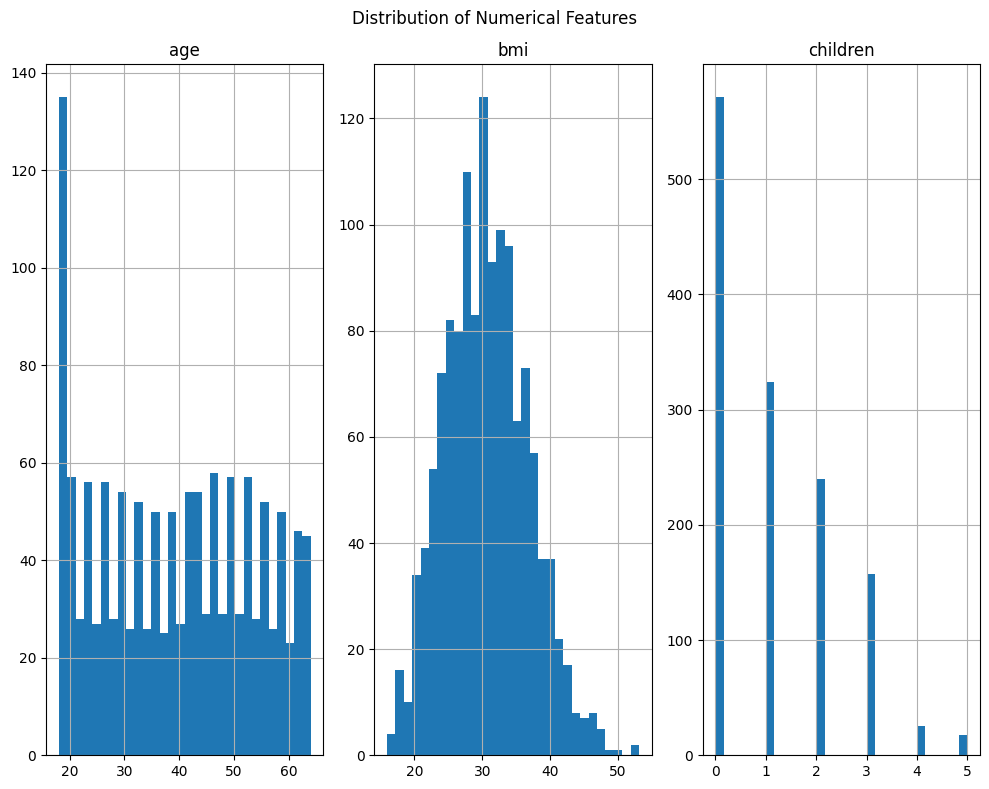

In [ ]:
import matplotlib.pyplot as plt
df_numeric_columns = [
    "age",
    "bmi",
    "children"
]
df[df_numeric_columns].hist(
    bins=30,
    figsize=(10,8),
    layout=(1,3)
)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [ ]:
#calculate skewness
df[df_numeric_columns].skew()

,0
age,0.051264
bmi,0.286014
children,0.935500


In [ ]:
#decide mean or median
for column in df_numeric_columns:
  skew_value = df[column].skew()
  if -0.5 < skew_value < 0.5:
    print(column,"-> use mean")
  else:
    print(column,"-> use median")

age -> use mean
bmi -> use mean
children -> use median


In [ ]:
# fill numerical missing value
df["age"]=df["age"].fillna(
    df["age"].mean()
)
df["bmi"]=df["bmi"].fillna(
    df["bmi"].mean()
)
df["children"]=df["children"].fillna(
    df["children"].median()
)

In [ ]:
df.isnull().sum()

,0
age,0
sex,2
bmi,0
children,0
smoker,2
region,2
charges,1


In [ ]:
# fill categorical missing values using mode
df["sex"]=df["sex"].fillna(
    df["sex"].mode()[0]
)
df["smoker"]=df["smoker"].fillna(
    df["smoker"].mode()[0]
)
df["region"]=df["region"].fillna(
    df["region"].mode()[0]
)
df.isnull().sum()


,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,1


In [ ]:
df=df.dropna(subset=["charges"])

In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df.shape

(1336, 7)

In [ ]:
# encode categorical colmns
df_encoded = pd.get_dummies(
    df,
    columns=["sex","smoker","region"],
    dtype=int
)
df_encoded.head()

,age,bmi,children,charges,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,19.0,27.900,0.0,16884.92400,1,0,0,1,0,0,0,1
1,18.0,33.770,1.0,1725.55230,0,1,1,0,0,0,1,0
2,28.0,33.000,3.0,4449.46200,0,1,1,0,0,0,1,0
3,33.0,22.705,0.0,21984.47061,0,1,1,0,0,1,0,0
4,32.0,28.880,0.0,3866.85520,0,1,1,0,0,1,0,0


In [ ]:
# separate input and target variable
X_df = df_encoded.drop(
    "charges",
    axis=1
)
y_df = df_encoded["charges"]
print("Input shape:",X_df.shape)
print("Target shape:",y_df.shape)

Input shape: (1336, 11)
Target shape: (1336,)


In [ ]:
# split traing data
from sklearn.model_selection import train_test_split
X_train_df,X_test_df,y_train_df,y_test_df = train_test_split(
    X_df,
    y_df,
    test_size=0.2,
    random_state=42
)
print("X_train_df shape:",X_train_df.shape[0])
print("X_test_df shape:",X_test_df.shape[0])


X_train_df shape: 1068
X_test_df shape: 268


In [ ]:
#standardize numerical columns
from sklearn.preprocessing import StandardScaler
df_scaler = StandardScaler()
scale_columns = [
    "age",
    "bmi",
    "children"
]
X_train_df_scaled = X_train_df.copy()
X_test_df_scaled = X_test_df.copy()


X_train_df_scaled[scale_columns]=df_scaler.fit_transform(
    X_train_df[scale_columns]
)
X_test_df_scaled[scale_columns]=df_scaler.transform(
    X_test_df[scale_columns]
)


In [ ]:
X_test_df_scaled

,age,bmi,children,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
900,0.702707,-1.345976,-0.924494,0,1,1,0,1,0,0,0
1064,-0.732097,-0.835828,2.433872,1,0,1,0,0,0,0,1
1256,0.846188,0.947625,1.594281,1,0,1,0,0,1,0,0
299,0.630967,-0.293433,-0.084903,1,0,1,0,0,1,0,0
238,-1.449499,-0.262014,-0.924494,0,1,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
535,-0.086435,-0.434819,-0.084903,0,1,1,0,1,0,0,0
543,1.061408,2.770765,-0.924494,1,0,0,1,0,0,1,0
897,-1.449499,-0.843269,-0.084903,0,1,1,0,0,1,0,0
1094,0.774447,0.503622,2.433872,1,0,1,0,0,0,0,1


In [ ]:
# build liner regression model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score

In [ ]:
linear_model = LinearRegression()
linear_model.fit(X_train_df_scaled,y_train_df)

LinearRegression()

In [ ]:
# tain the model
linear_model.fit(
    X_train_df_scaled,
    y_train_df
)
print("Linear Rgression model training complete")

Linear Rgression model training complete


In [ ]:
# predit test data
pred = linear_model.predict(
    X_test_df_scaled
)



In [ ]:
#compare actual and predicted values
df_result = pd.DataFrame({
    "Actual":y_test_df.values,
    "Predicted":pred
})
df_result.head(10)

,Actual,Predicted
0,8688.85885,8392.951121
1,5708.86700,5425.272329
2,11436.73815,14582.807279
3,9249.49520,10257.781703
4,17352.68030,26085.919365
5,1622.18850,2057.528180
6,5354.07465,4609.143440
7,12928.79110,14048.323478
8,9140.95100,11841.734730
9,10264.44210,11664.107516


In [ ]:
# Evalute the model
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
mae = mean_absolute_error(
    y_test_df,
    pred
)
mse = mean_squared_error(
    y_test_df,
    pred
)
rmse = mse**0.5
r2 = r2_score(
    y_test_df,
    pred
)
print("MAE:",mae)
print("MSE:",mse)
print("RMSE:",rmse)
print("R2:",r2)

MAE: 4331.875132152566
MSE: 40197109.01046901
RMSE: 6340.119006017869
R2: 0.7346743443721404


In [ ]:
# to create a unkonown data
new_customer = pd.DataFrame({
    "age":[35],
    "sex":["male"],
    "bmi":[30],
    "children":[2],
    "smoker":["yes"],
    "region":["southeast"]
})
new_customer

,age,sex,bmi,children,smoker,region
0,35,male,30,2,yes,southeast


In [ ]:
new_customer_encoded = pd.get_dummies(
    new_customer,
    columns=["sex","smoker","region"],
    dtype=int
)
new_customer_encoded

,age,bmi,children,sex_male,smoker_yes,region_southeast
0,35,30,2,1,1,1


In [ ]:
# day three



In [ ]:
# to create a new dummy customer
new_customer = pd.DataFrame({
    "age":[35],
    "sex":["male"],
    "bmi":[30],
    "children":[2],
    "smoker":["yes"],
    "region":["southeast"]
})
print("---New Customer Profile---")
display(new_customer)
new_customer_encoded = pd.get_dummies(new_customer,columns=["sex","smoker","region"],dtype=int)
new_customer_encoded = new_customer_encoded.reindex(columns=X_df.columns,fill_value=0)

# standardize numeric columns using the already fitted scaler
new_customer_scaled = new_customer_encoded.copy()
scale_columns = ["age", "bmi", "children"]
new_customer_scaled[scale_columns] = df_scaler.transform(new_customer_encoded[scale_columns])

#predict the charges
preicted_charge = linear_model.predict(new_customer_scaled)[0]
print(f"\nPredicted Insurance charges:${preicted_charge:,.2f}")
print("Predicted Charges:", preicted_charge)

---New Customer Profile---


,age,sex,bmi,children,smoker,region
0,35,male,30,2,yes,southeast



Predicted Insurance charges:$31,028.55
Predicted Charges: 31028.54748319466


In [ ]:
# streamlit
import joblib
joblib.dump(linear_model,'model.pkl')
print("Model dumped!")

Model dumped!
